# Importing necessary libraries

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os



## Loading dataset

In [16]:
# Load dataset and parse date
df = pd.read_csv('data/raw/train.csv')
df['date'] = pd.to_datetime(df['date'])

# Exploratory Data Analysis (EDA) - Sales Forecasting
This notebook contains the visual insights, data distribution, and pattern analysis for the data.

In [17]:
df.head()

,date,store,item,sales
0,2013-01-01,1,1,13
1,2013-01-02,1,1,11
2,2013-01-03,1,1,14
3,2013-01-04,1,1,13
4,2013-01-05,1,1,10


### Statistical Summary & Skewness
Checking basic distribution metrics of the sales target.

In [25]:
print('Basic Statistical summery')
print("Dataset Shape:", df.shape)
print('\n', df.describe())
print(f"\n\nChecking null values :\n{df.isnull().sum()}")

Basic Statistical summery
Dataset Shape: (913000, 4)

                       date          store           item          sales
count               913000  913000.000000  913000.000000  913000.000000
mean   2015-07-02 12:00:00       5.500000      25.500000      52.250287
min    2013-01-01 00:00:00       1.000000       1.000000       0.000000
25%    2014-04-02 00:00:00       3.000000      13.000000      30.000000
50%    2015-07-02 12:00:00       5.500000      25.500000      47.000000
75%    2016-10-01 00:00:00       8.000000      38.000000      70.000000
max    2017-12-31 00:00:00      10.000000      50.000000     231.000000
std                    NaN       2.872283      14.430878      28.801144


Checking null values :
date     0
store    0
item     0
sales    0
dtype: int64


### Daily Sales Trend Over Time
Visualizing non-linear patterns and long-term trends.

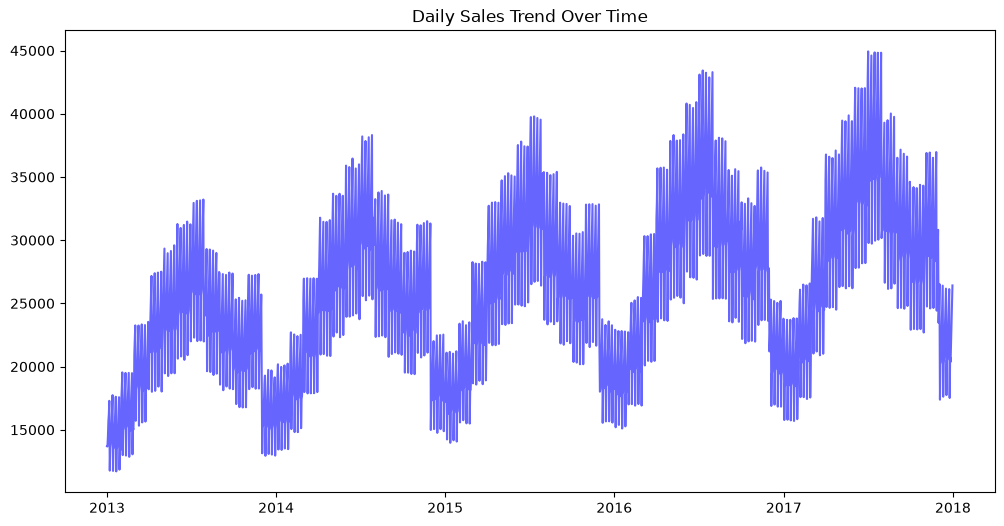

In [26]:
daily_sales = df.groupby('date')['sales'].sum().reset_index()
plt.figure(figsize=(12, 6))
plt.plot(daily_sales['date'], daily_sales['sales'], color='blue', alpha=0.6)
plt.title('Daily Sales Trend Over Time')Description: This line plot visualizes the total daily sales over the entire timeline (from 2013 to 2018).   Insight: The data clearly exhibits a strong non-linear and seasonal pattern. Every year, sales systematically spike during certain months and drop during others. There is also a gradual upward trend in overall volume across the years, meaning standard linear models will fail here without capturing time-based features and seasonality.
plt.show()

Description: This line plot visualizes the total daily sales over the entire timeline (from 2013 to 2018).  

Insight: The data clearly exhibits a strong non-linear and seasonal pattern. Every year, sales systematically spike during certain months and drop during others. There is also a gradual upward trend in overall volume across the years, meaning standard linear models will fail here without capturing time-based features and seasonality.

### Outlier Detection via Boxplot

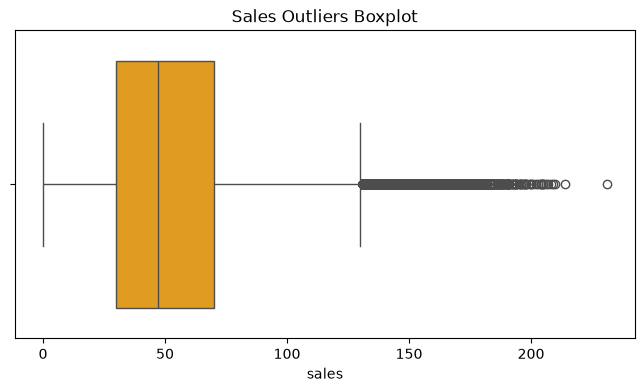

In [27]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=df['sales'], color='orange')
plt.title('Sales Outliers Boxplot')
plt.show()

Description: This boxplot displays the distribution of the sales column and highlights values lying outside the interquartile range (IQR).

Insight: As seen on the right side of the plot, there are numerous outliers (extreme high sales values) stretching beyond 130 up to 230+. These represent unusual peak sales days (possibly due to holidays, promotions, or bulk purchases) which need to be handled carefully during data preprocessing so they do not negatively skew model training.

### Monthly Seasonality Pattern

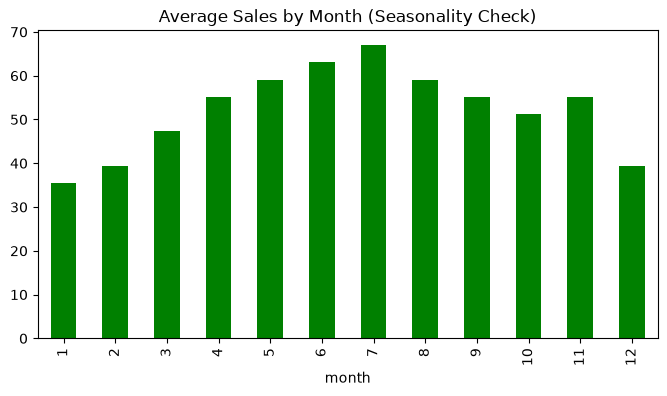

In [29]:
df['month'] = df['date'].dt.month
monthly_avg = df.groupby('month')['sales'].mean()
plt.figure(figsize=(8, 4))
monthly_avg.plot(kind='bar', color='green')
plt.title('Average Sales by Month (Seasonality Check)')
plt.show()

Description: This bar chart aggregates the average sales grouped by each calendar month (1 to 12).

Insight: It confirms a very clear seasonal cycle. Sales are lowest at the beginning and end of the year (months 1, 2, and 12) and steadily climb to a peak during the middle months of the year (specifically peaking around June and July, months 6 and 7). This justifies extracting month-based features for the machine learning model.